### **Problem 1 (c)**

In [1]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_parquet("taxi_trips.parquet")
X = df.drop(columns="trip_duration").values
y = df["trip_duration"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train, X_val, X_test, y_train, y_val, y_test = [
    torch.tensor(a, dtype=torch.float32)
    for a in (X_train, X_val, X_test, y_train, y_val, y_test)
]

In [2]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(7, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        out = self.net(x)
        return out[:, 0], torch.exp(out[:, 1])

def loss_fn(mu, sigma, y):
    return (torch.log(sigma) + (y - mu)**2 / (2 * sigma**2)).mean()

In [3]:
torch.manual_seed(42)
model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_train, y_train), batch_size=1024, shuffle=True)

best_loss = float("inf")

for epoch in range(30):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        mu, sigma = model(xb)
        loss = loss_fn(mu, sigma, yb)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        mu, sigma = model(X_val)
        val_loss = loss_fn(mu, sigma, y_val).item()

    if val_loss < best_loss:
        best_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)

<All keys matched successfully>

In [4]:
model.eval()
with torch.no_grad():
    mu, sigma = model(X_test)

    baseline_mse = ((y_test - y_train.mean())**2).mean().item()
    model_mse = ((y_test - mu)**2).mean().item()
    test_nll = loss_fn(mu, sigma, y_test).item()

print(f"Baseline MSE: {baseline_mse:.4f}")
print(f"MLP MSE: {model_mse:.4f}")
print(f"MLP Gaussian NLL: {test_nll:.4f}")

Baseline MSE: 60.1694
MLP MSE: 18.2073
MLP Gaussian NLL: 1.8623


### **Problem 1 (e)**

In [5]:
from torch.distributions import Normal

prob = Normal(mu, sigma).cdf(torch.tensor(45.0))
pred = prob > 0.5
actual = y_test < 45

accuracy = (pred == actual).float().mean().item()
brier = ((prob - actual.float())**2).mean().item()

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Brier Score: {brier:.4f}")

Test Accuracy: 0.9959
Brier Score: 0.0034


### **Problem 2 (a)**

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("retail.csv")

print("Shape:", df.shape)
print("Unique StockCode:", df["StockCode"].nunique())
print("Unique CustomerID:", df["CustomerID"].nunique())

train, temp = train_test_split(df, test_size=0.3, random_state=42)
val, test = train_test_split(temp, test_size=0.5, random_state=42)

Shape: (397924, 3)
Unique StockCode: 3665
Unique CustomerID: 4339


**Comments**

The dataset contains 397,924 observations, with 3,665 unique StockCode values and 4,339 unique CustomerID values. I think one-hot encoding may be inefficient because it would create 8,004 features. Therefore, target encoding or embeddings may be better alternatives.

### **Problem 2 (b)**

In [2]:
import numpy as np
import category_encoders as ce

features = ["StockCode", "CustomerID"]

y_train = np.log1p(train["Quantity"])
y_val = np.log1p(val["Quantity"])
y_test = np.log1p(test["Quantity"])

encoder = ce.TargetEncoder(cols=features)
X_train = encoder.fit_transform(train[features], y_train)
X_val = encoder.transform(val[features])
X_test = encoder.transform(test[features])

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

model = Ridge()
model.fit(X_train, y_train)

print("Validation Log MSE:", mean_squared_error(y_val, model.predict(X_val)))
print("Test Log MSE:", mean_squared_error(y_test, model.predict(X_test)))
print("Test MSE:", mean_squared_error(test["Quantity"], np.expm1(model.predict(X_test))))

Validation Log MSE: 0.36730818621859057
Test Log MSE: 0.36373210660063393
Test MSE: 1187.2824548941953


**Comments**

I used a log transformation to reduce the influence of extreme Quantity values. The model achieved a test log MSE of 0.3637 and a test MSE of 1187.28 on the original scale. Compared to the previous model trained on raw Quantity, the original-scale test MSE decreased significantly.

### **Problem 2 (c)**

In [5]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

cols = ["StockCode", "CustomerID"]
sizes = []

for col in cols:
    mapping = {v: i + 1 for i, v in enumerate(train[col].unique())}
    sizes.append(len(mapping) + 1)
    for df in (train, val, test):
        df[col + "_idx"] = df[col].map(mapping).fillna(0).astype(int)

def tensors(df):
    X = torch.tensor(df[[c + "_idx" for c in cols]].values, dtype=torch.long)
    y = torch.tensor(np.log1p(df["Quantity"].values), dtype=torch.float32)
    return X, y

X_train, y_train = tensors(train)
X_val, y_val = tensors(val)
X_test, y_test = tensors(test)

In [6]:
class EmbeddingMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb1 = nn.Embedding(sizes[0], 8)
        self.emb2 = nn.Embedding(sizes[1], 8)
        self.net = nn.Sequential(nn.Linear(16, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        z = torch.cat([self.emb1(x[:, 0]), self.emb2(x[:, 1])], dim=1)
        return self.net(z).squeeze(-1)

In [12]:
torch.manual_seed(42)
model = EmbeddingMLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_train, y_train), batch_size=1024, shuffle=True)

best = float("inf")

for epoch in range(30):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = nn.functional.mse_loss(model(xb), yb)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = nn.functional.mse_loss(model(X_val), y_val).item()

    if val_loss < best:
        best = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)

with torch.no_grad():
    print("Validation Log MSE:", nn.functional.mse_loss(model(X_val), y_val).item())
    print("Test Log MSE:", nn.functional.mse_loss(model(X_test), y_test).item())

Validation Log MSE: 0.30359524488449097
Test Log MSE: 0.30507054924964905


**Comments**

The embedding model achieved a test log MSE of 0.3051, compared to 0.3637 for the target encoding model. I think this suggests that learned embeddings are more effective at capturing patterns in these high-cardinality categorical features.

### **Problem 2 (d)**

In [9]:
T_train = torch.tensor(encoder.transform(train[cols]).values, dtype=torch.float32)
T_val = torch.tensor(encoder.transform(val[cols]).values, dtype=torch.float32)
T_test = torch.tensor(encoder.transform(test[cols]).values, dtype=torch.float32)

In [10]:
class CombinedMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb1 = nn.Embedding(sizes[0], 8)
        self.emb2 = nn.Embedding(sizes[1], 8)
        self.net = nn.Sequential(
            nn.Linear(18, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x, t):
        z = torch.cat([self.emb1(x[:, 0]), self.emb2(x[:, 1]), t], dim=1)
        return self.net(z).squeeze(-1)

In [11]:
torch.manual_seed(42)
combined = CombinedMLP()
optimizer = torch.optim.Adam(combined.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_train, T_train, y_train), batch_size=1024, shuffle=True)

best = float("inf")

for epoch in range(30):
    combined.train()
    for xb, tb, yb in loader:
        optimizer.zero_grad()
        loss = nn.functional.mse_loss(combined(xb, tb), yb)
        loss.backward()
        optimizer.step()

    combined.eval()
    with torch.no_grad():
        val_loss = nn.functional.mse_loss(combined(X_val, T_val), y_val).item()

    if val_loss < best:
        best = val_loss
        best_state = {k: v.clone() for k, v in combined.state_dict().items()}

combined.load_state_dict(best_state)
combined.eval()

with torch.no_grad():
    pred_val = combined(X_val, T_val)
    pred_test = combined(X_test, T_test)

    print("Validation Log MSE:", nn.functional.mse_loss(pred_val, y_val).item())
    print("Test Log MSE:", nn.functional.mse_loss(pred_test, y_test).item())
    print("Test MSE:", mean_squared_error(test["Quantity"], np.expm1(pred_test.numpy())))

Validation Log MSE: 0.30482637882232666
Test Log MSE: 0.30461400747299194
Test MSE: 1067.1341552734375


**Comments**

The combined model achieved a test log MSE of 0.3046, slightly better than the embedding-only model (0.3051) and the target encoding model (0.3637). I think this suggests that target-encoded features may provide some additional information, but the improvement is very small.

### **Problem 2 (e)**

I think the embedding model performs well because it can learn more flexible representations of StockCode and CustomerID. In contrast, target encoding only summarizes each category using its average log-transformed Quantity, which may not capture more complex patterns.

The combined model performs slightly better than the embedding-only model (0.3046 vs. 0.3051 in test log MSE). I think this suggests that target-encoded features may provide some additional useful information, although the improvement is very small. Overall, learned embeddings seem more effective for this dataset, and the log transformation helps reduce the influence of extreme Quantity values.

### **Problem 3 (a)**

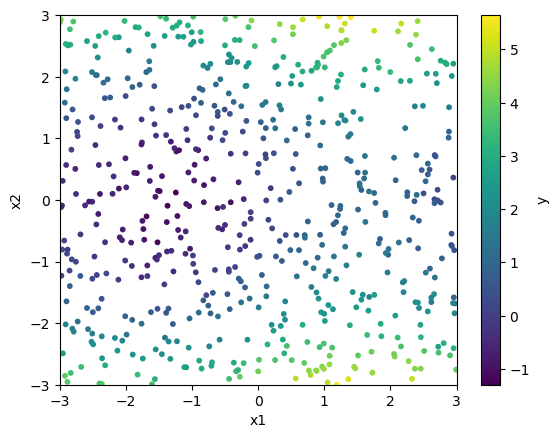

In [1]:
import numpy as np
import matplotlib.pyplot as plt

train = np.loadtxt("train.csv", delimiter=",", skiprows=1)

plt.scatter(train[:, 0], train[:, 1], c=train[:, 2], s=10)
plt.colorbar(label="y")
plt.xlabel("x1")
plt.ylabel("x2")
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.show()

### **Problem 3 (b)**

In [2]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

val = np.loadtxt("val.csv", delimiter=",", skiprows=1)
X_train, y_train = train[:, :2], train[:, 2]
X_val, y_val = val[:, :2], val[:, 2]

D_values = [10, 20, 50, 100, 200, 500]
train_mse, val_mse = [], []

rng = np.random.default_rng(42)
W = rng.normal(size=(2, max(D_values)//2))
b = rng.uniform(0, 2*np.pi, size=max(D_values)//2)

def features(X, D):
    A = X @ W[:, :D//2] + b[:D//2]
    return np.column_stack([np.sin(A), np.cos(A)])

for D in D_values:
    model = Ridge(alpha=0.001)
    model.fit(features(X_train, D), y_train)

    train_mse.append(mean_squared_error(y_train, model.predict(features(X_train, D))))
    val_mse.append(mean_squared_error(y_val, model.predict(features(X_val, D))))

best_D = D_values[np.argmin(val_mse)]
print("Best D:", best_D)
print("Best Validation MSE:", min(val_mse))

Best D: 100
Best Validation MSE: 0.03801199013871969


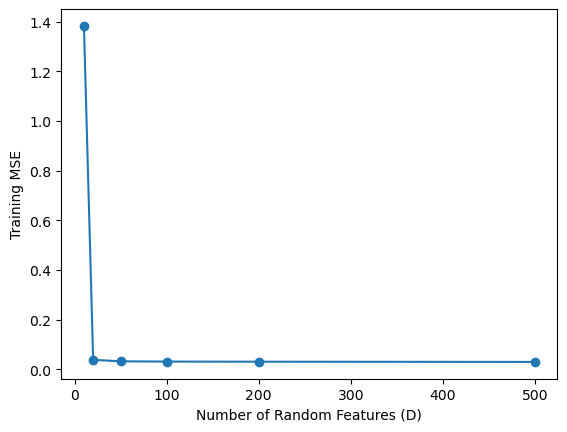

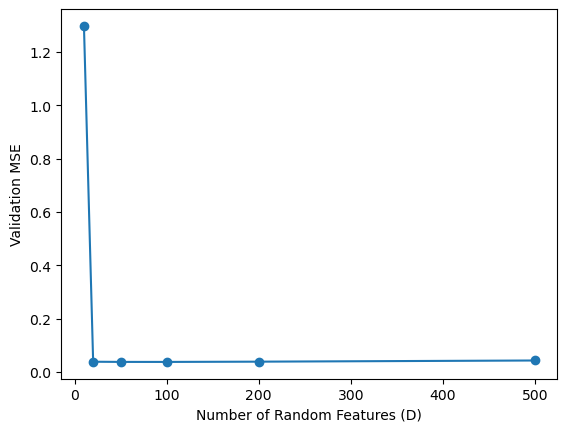

In [3]:
plt.figure()
plt.plot(D_values, train_mse, marker="o")
plt.xlabel("Number of Random Features (D)")
plt.ylabel("Training MSE")
plt.show()

plt.figure()
plt.plot(D_values, val_mse, marker="o")
plt.xlabel("Number of Random Features (D)")
plt.ylabel("Validation MSE")
plt.show()

### **Problem 3 (c)**

In [4]:
import torch
import torch.nn as nn

torch.manual_seed(42)

Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
Xv = torch.tensor(X_val, dtype=torch.float32)
yv = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

H_values = [10, 20, 50, 100, 200, 500]
train_mse_mlp, val_mse_mlp = [], []

def train_mlp(H):
    model = nn.Sequential(
        nn.Linear(2, H),
        nn.ReLU(),
        nn.Linear(H, 1)
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    for _ in range(500):
        optimizer.zero_grad()
        loss = nn.functional.mse_loss(model(Xtr), ytr)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        tr = nn.functional.mse_loss(model(Xtr), ytr).item()
        va = nn.functional.mse_loss(model(Xv), yv).item()

    return model, tr, va

best_mlp, best_val_mlp, best_H = None, float("inf"), None

for H in H_values:
    model, tr, va = train_mlp(H)
    train_mse_mlp.append(tr)
    val_mse_mlp.append(va)

    if va < best_val_mlp:
        best_mlp, best_val_mlp, best_H = model, va, H

print("Best H:", best_H)
print("Best Validation MSE:", best_val_mlp)

Best H: 500
Best Validation MSE: 0.04921687766909599


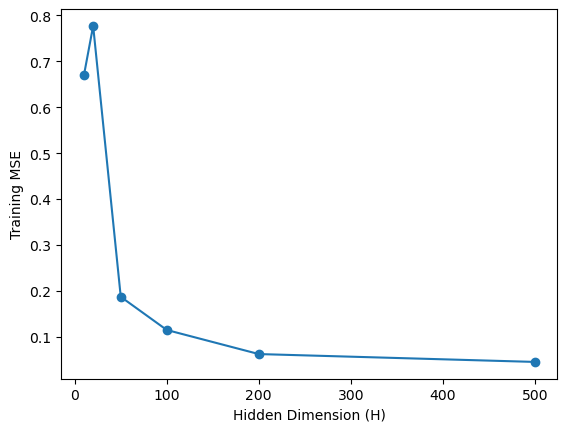

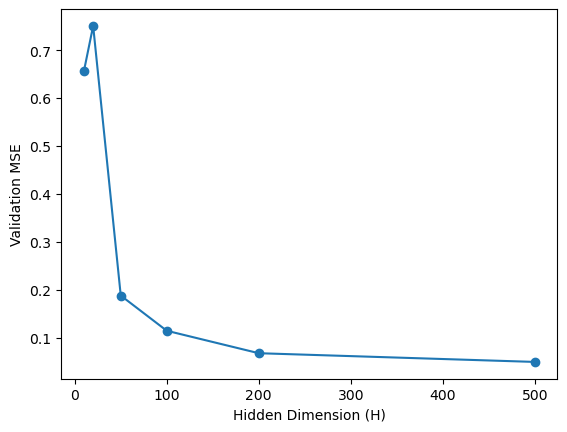

In [5]:
plt.figure()
plt.plot(H_values, train_mse_mlp, marker="o")
plt.xlabel("Hidden Dimension (H)")
plt.ylabel("Training MSE")
plt.show()

plt.figure()
plt.plot(H_values, val_mse_mlp, marker="o")
plt.xlabel("Hidden Dimension (H)")
plt.ylabel("Validation MSE")
plt.show()

### **Problem 3 (d)**

In [7]:
rks = Ridge(alpha=0.001)
rks.fit(features(X_train, best_D), y_train)

test = np.loadtxt("test.csv", delimiter=",", skiprows=1)
X_test = test[:, :2]

rks_pred = rks.predict(features(X_test, best_D))
mlp_pred = best_mlp(torch.tensor(X_test, dtype=torch.float32)).detach().numpy().ravel()

np.savetxt("rks_test_predictions.csv", rks_pred, delimiter=",")
np.savetxt("mlp_test_predictions.csv", mlp_pred, delimiter=",")

print("RKS Validation MSE:", min(val_mse))
print("MLP Validation MSE:", best_val_mlp)

RKS Validation MSE: 0.03801199013871969
MLP Validation MSE: 0.04921687766909599


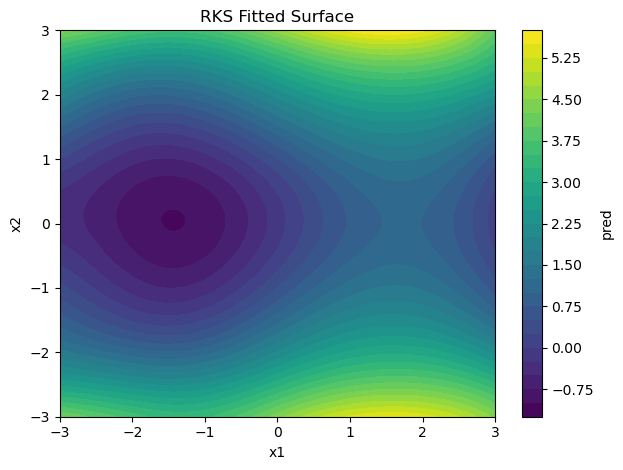

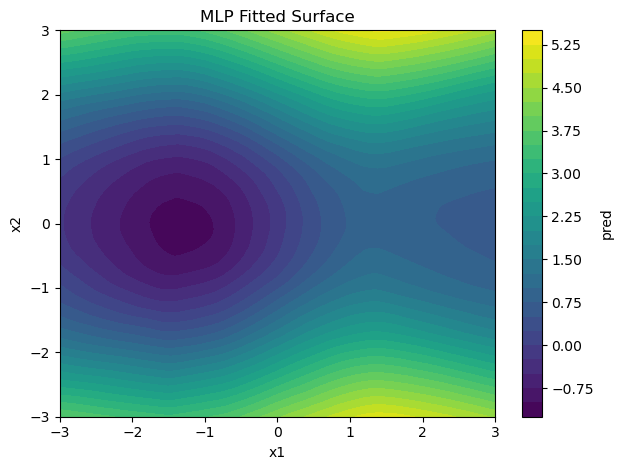

In [8]:
from plotting import plot_surface_2d

plot_surface_2d(
    lambda X: rks.predict(features(X, best_D)),
    (-3, 3), (-3, 3),
    title="RKS Fitted Surface",
    filename="rks_surface.png"
)

plot_surface_2d(
    best_mlp,
    (-3, 3), (-3, 3),
    title="MLP Fitted Surface",
    filename="mlp_surface.png"
)

**Comments**

The RKS model achieved a validation MSE of 0.0380, slightly better than the MLP model (0.0492). I think RKS performs better because its random nonlinear features can capture the smooth patterns in this dataset effectively.

Both fitted surfaces look similar to the training data visualization in part (a). They capture the low-value region around x1 = -1.5 and x2 = 0, as well as the increasing y values when |x2| becomes larger. Overall, both models seem to learn the underlying nonlinear structure well.